# Data Acquisition and Exploration

This notebook loads and explores the property condition assessment dataset from XML annotation files.

## Setup and Imports

In [24]:
import os
import sys
import importlib

# Add project root to Python path
if os.path.exists(os.path.join(os.getcwd(), 'src')):
    project_root = os.getcwd()
else:
    project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))

if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Force reload modules to pick up Config changes
if 'src.config' in sys.modules:
    importlib.reload(sys.modules['src.config'])
if 'src.data_loader' in sys.modules:
    importlib.reload(sys.modules['src.data_loader'])

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data_loader import DataLoader
from src.config import Config

# Verify paths
print("🔍 Verifying configuration:")
print(f"   ANNOTATIONS_DIR: {Config.ANNOTATIONS_DIR}")
print(f"   ANNOTATIONS_DIR exists: {os.path.exists(Config.ANNOTATIONS_DIR)}")
print(f"   RAW_IMAGES_DIR: {Config.RAW_IMAGES_DIR}")
print(f"   RAW_IMAGES_DIR exists: {os.path.exists(Config.RAW_IMAGES_DIR)}")

# Set up plotting style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

🔍 Verifying configuration:
   ANNOTATIONS_DIR: /home/exouser/DSM-property-condition-assessment/Data/annotation
   ANNOTATIONS_DIR exists: True
   RAW_IMAGES_DIR: /home/exouser/DSM-property-condition-assessment/Data/extractedimages
   RAW_IMAGES_DIR exists: True


In [25]:
# Load annotations from XML files
loader = DataLoader()

# Check what paths DataLoader is using
print(f"🔍 DataLoader paths:")
print(f"   loader.annotations_dir: {loader.annotations_dir}")
print(f"   loader.annotations_dir exists: {os.path.exists(loader.annotations_dir)}")

# Check XML files directly
from glob import glob
xml_pattern = os.path.join(loader.annotations_dir, "*.xml")
xml_files = glob(xml_pattern)
print(f"\n🔍 XML files check:")
print(f"   Pattern: {xml_pattern}")
print(f"   Found {len(xml_files)} XML files")
if xml_files:
    print(f"   Sample files: {xml_files[:3]}")

# Load data
df = loader.load_annotations()

print(f"\n✅ Loaded {len(df)} images from annotation files")
print(f"DataFrame columns: {df.columns.tolist()}")
if not df.empty:
    print(f"\nFirst few rows:")
    display(df.head())
else:
    print("\n⚠️ DataFrame is empty! Check the debug output above.")

🔍 DataLoader paths:
   loader.annotations_dir: /home/exouser/DSM-property-condition-assessment/Data/annotation
   loader.annotations_dir exists: True

🔍 XML files check:
   Pattern: /home/exouser/DSM-property-condition-assessment/Data/annotation/*.xml
   Found 5 XML files
   Sample files: ['/home/exouser/DSM-property-condition-assessment/Data/annotation/NHTyp5.xml', '/home/exouser/DSM-property-condition-assessment/Data/annotation/NHTyp3.xml', '/home/exouser/DSM-property-condition-assessment/Data/annotation/NHTyp4.xml']
🔍 DataLoader debug:
   annotations_dir: /home/exouser/DSM-property-condition-assessment/Data/annotation
   annotations_dir exists: True
   glob pattern: /home/exouser/DSM-property-condition-assessment/Data/annotation/*.xml
   XML files found: 5
   Sample XML: /home/exouser/DSM-property-condition-assessment/Data/annotation/NHTyp5.xml

✅ Loaded 1856 images from annotation files
DataFrame columns: ['dataset', 'image_id', 'file_name', 'image_path', 'expert_score']

First few

,dataset,image_id,file_name,image_path,expert_score
0,NHTyp5,0,NHTyp5/ATT12295_PropertyConditionAssessment_im...,/home/exouser/DSM-property-condition-assessmen...,NaN
1,NHTyp5,1,NHTyp5/ATT12318_PropertyConditionAssessment_im...,/home/exouser/DSM-property-condition-assessmen...,NaN
2,NHTyp5,2,NHTyp5/ATT12341_PropertyConditionAssessment_im...,/home/exouser/DSM-property-condition-assessmen...,NaN
3,NHTyp5,3,NHTyp5/ATT12361_PropertyConditionAssessment_im...,/home/exouser/DSM-property-condition-assessmen...,NaN
4,NHTyp5,4,NHTyp5/ATT12541_PropertyConditionAssessment_im...,/home/exouser/DSM-property-condition-assessmen...,NaN


In [26]:
# Dataset overview and statistics
scored_df = df[df['expert_score'].notna()].copy()
scored_df['expert_score'] = scored_df['expert_score'].astype(int)

print("📊 Dataset Overview:")
print("=" * 80)
print(f"Total images in annotation files: {len(df)}")
print(f"Total images with expert scores: {len(scored_df)}")
print(f"Images missing expert scores: {len(df) - len(scored_df)}")
print(f"Expert score coverage: {len(scored_df) / len(df) * 100:.2f}%")

print("\nScore distribution:")
score_dist = scored_df['expert_score'].value_counts().sort_index()
print(score_dist)

print(f"\nAverage Score: {scored_df['expert_score'].mean():.2f}")
print(f"Median Score: {scored_df['expert_score'].median():.2f}")

# Display first few rows
display(scored_df.head())

📊 Dataset Overview:
Total images in annotation files: 1856
Total images with expert scores: 1686
Images missing expert scores: 170
Expert score coverage: 90.84%

Score distribution:
expert_score
1    211
2    544
3    607
4    283
5     41
Name: count, dtype: int64

Average Score: 2.64
Median Score: 3.00


,dataset,image_id,file_name,image_path,expert_score
22,NHTyp5,22,NHTyp5/ATT13328_PropertyConditionAssessment_im...,/home/exouser/DSM-property-condition-assessmen...,4
23,NHTyp5,23,NHTyp5/ATT13335_PropertyConditionAssessment_im...,/home/exouser/DSM-property-condition-assessmen...,4
24,NHTyp5,24,NHTyp5/ATT13344_PropertyConditionAssessment_im...,/home/exouser/DSM-property-condition-assessmen...,4
25,NHTyp5,25,NHTyp5/ATT13347_PropertyConditionAssessment_im...,/home/exouser/DSM-property-condition-assessmen...,4
27,NHTyp5,27,NHTyp5/ATT13353_PropertyConditionAssessment_im...,/home/exouser/DSM-property-condition-assessmen...,5


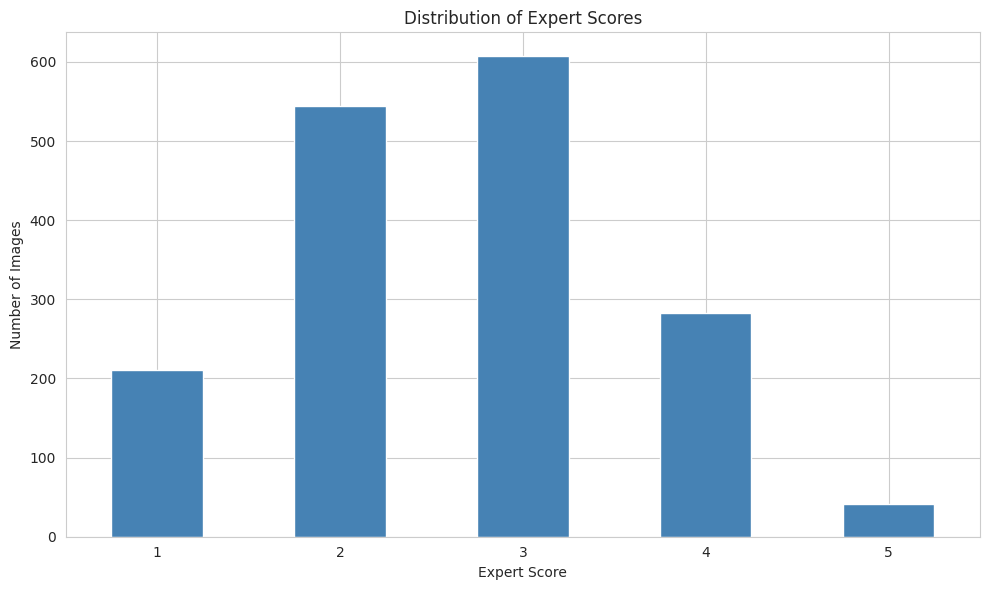

In [27]:
# Visualize score distribution
fig, ax = plt.subplots(figsize=(10, 6))
score_dist.plot(kind='bar', ax=ax, color='steelblue')
ax.set_xlabel('Expert Score')
ax.set_ylabel('Number of Images')
ax.set_title('Distribution of Expert Scores')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()